<a href="https://colab.research.google.com/github/aic309/PCD_Assignment_3/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Imports

In [10]:
import numpy as np
import matplotlib.pyplot as plt

## 2. Load image


In [11]:
IMAGE_PATH = "3_cells.png"

gt = None
try:
    from PIL import Image
    img = np.array(Image.open(IMAGE_PATH).convert("RGB"))
    print("Loaded", IMAGE_PATH, img.shape)
except Exception:
    print("Image not found -> using synthetic test image")
    rng = np.random.default_rng(0)
    H, W = 256, 256
    yy, xx = np.mgrid[0:H, 0:W]
    gt = ((xx-80)**2 + (yy-90)**2 < 40**2) | ((xx-180)**2 + (yy-80)**2 < 30**2) \
         | ((abs(xx-130) < 50) & (abs(yy-190) < 25))
    base = np.where(gt, 170.0, 70.0)
    noisy = base + rng.normal(0, 40, (H, W))

    r = rng.random((H, W))
    noisy[r < 0.02] = 0
    noisy[r > 0.98] = 255
    img = np.clip(noisy, 0, 255).astype(np.uint8)
    img = np.stack([img]*3, axis=-1)

Loaded 3_cells.png (400, 500, 3)


## 3. Convert to grayscale
$$Y = 0.299R + 0.587G + 0.114B$$

In [12]:
def to_gray(rgb):
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    return (0.299*r + 0.587*g + 0.114*b).astype(np.uint8)

gray = to_gray(img)

## 4. Segmentation: Otsu threshold
Try every threshold $t$ (0–255). Pick the one with the biggest **between-class variance**:

$$\sigma_b^2(t) = w_0(t)\,w_1(t)\,[\mu_0(t)-\mu_1(t)]^2$$

In [13]:
def otsu_threshold(gray):
    hist = np.zeros(256)
    for v in gray.ravel():
        hist[v] += 1
    p = hist / hist.sum()

    best_t, best_var = 0, -1
    for t in range(256):
        w0 = p[:t+1].sum()
        w1 = 1 - w0
        if w0 == 0 or w1 == 0:
            continue
        mu0 = (np.arange(t+1) * p[:t+1]).sum() / w0
        mu1 = (np.arange(t+1, 256) * p[t+1:]).sum() / w1
        var_b = w0 * w1 * (mu0 - mu1) ** 2
        if var_b > best_var:
            best_var, best_t = var_b, t
    return best_t

def segment(gray):
    t = otsu_threshold(gray)
    return (gray > t).astype(np.uint8), t

seg, t = segment(gray)
print("Otsu threshold =", t)

Otsu threshold = 150


## 5. Morphology (by hand)
Slide a structuring element (SE) over the binary image.

| Operation | Rule |
|---|---|
| Erosion | pixel = 1 only if **all** SE neighbors are 1 |
| Dilation | pixel = 1 if **any** SE neighbor is 1 |
| Opening | erosion → dilation (removes small white noise) |
| Closing | dilation → erosion (fills small black holes) |

In [14]:
def make_se(size=3):
    return np.ones((size, size), dtype=np.uint8)

def erode(img, se):
    h, w = img.shape
    kh, kw = se.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img, ((ph, ph), (pw, pw)), constant_values=0)
    out = np.ones_like(img)
    for i in range(kh):
        for j in range(kw):
            if se[i, j]:
                out &= pad[i:i+h, j:j+w]
    return out

def dilate(img, se):
    h, w = img.shape
    kh, kw = se.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img, ((ph, ph), (pw, pw)), constant_values=0)
    out = np.zeros_like(img)
    for i in range(kh):
        for j in range(kw):
            if se[i, j]:
                out |= pad[i:i+h, j:j+w]
    return out

def opening(img, se):
    return dilate(erode(img, se), se)

def closing(img, se):
    return erode(dilate(img, se), se)

## 6. Apply morphology
Opening first (remove white specks), then closing (fill holes).

In [15]:
se = make_se(5)

eroded  = erode(seg, se)
dilated = dilate(seg, se)
opened  = opening(seg, se)
final   = closing(opened, se)

## 7. Show each operation

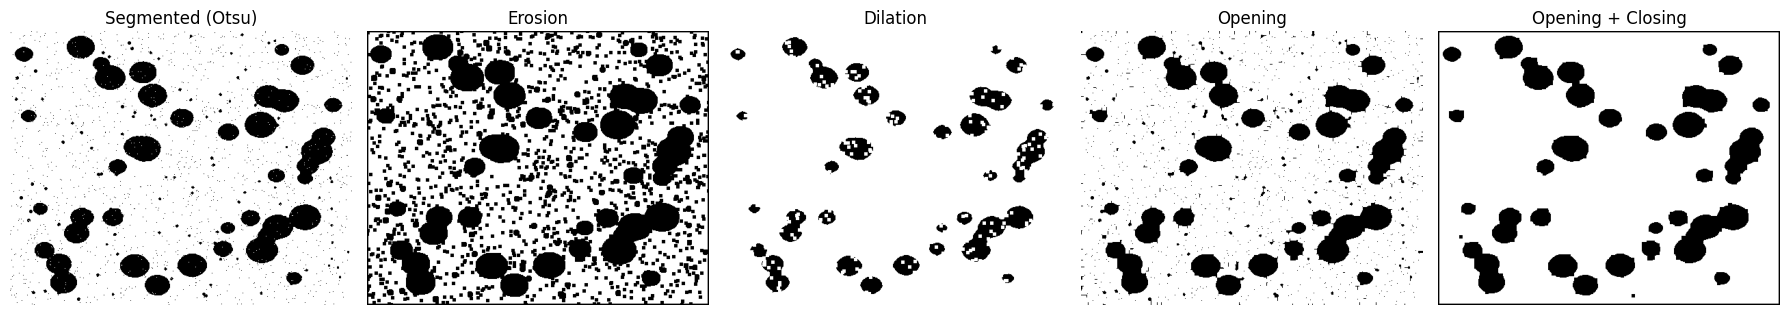

In [16]:
steps = [("Segmented (Otsu)", seg), ("Erosion", eroded), ("Dilation", dilated),
         ("Opening", opened), ("Opening + Closing", final)]

fig, ax = plt.subplots(1, 5, figsize=(18, 4))
for a, (name, im) in zip(ax, steps):
    a.imshow(im, cmap="gray"); a.set_title(name); a.axis("off")
plt.tight_layout(); plt.show()

## 8. Compare: without vs with morphology

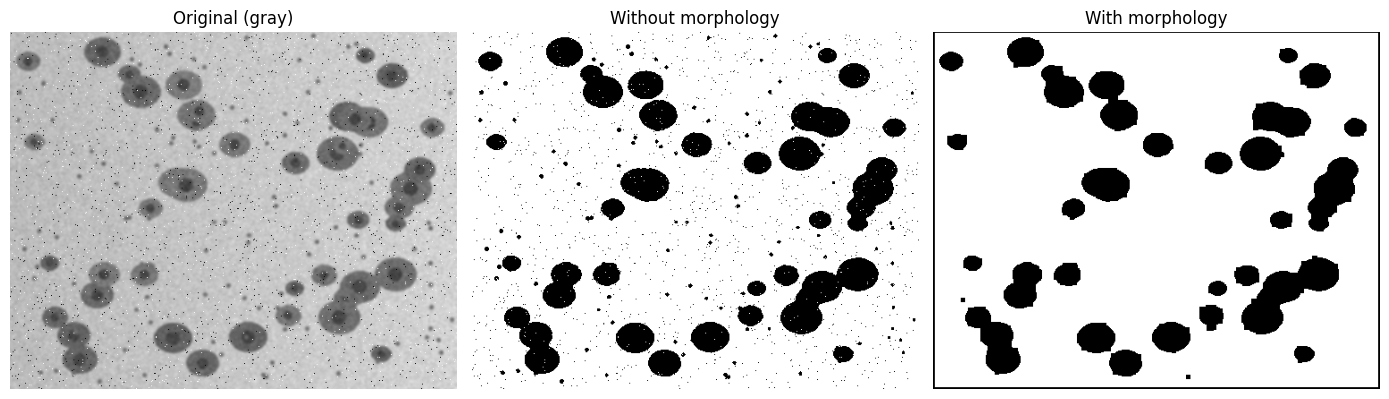

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(14, 5))
ax[0].imshow(gray, cmap="gray");  ax[0].set_title("Original (gray)")
ax[1].imshow(seg, cmap="gray");   ax[1].set_title("Without morphology")
ax[2].imshow(final, cmap="gray"); ax[2].set_title("With morphology")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Numbers


$$IoU = \frac{|A \cap B|}{|A \cup B|}$$

In [18]:
def iou(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return (a & b).sum() / max((a | b).sum(), 1)

if gt is not None:
    print(f"IoU without morphology: {iou(seg, gt):.3f}")
    print(f"IoU with morphology   : {iou(final, gt):.3f}")
else:
    print("White pixels without morphology:", int(seg.sum()))
    print("White pixels with morphology   :", int(final.sum()))

White pixels without morphology: 167013
White pixels with morphology   : 165060
